# ResNet50 v2/v3/v4 with validation
This notebook explore the training of a classification model, over a compressed image dataset. The compression has been implemented using the GD-compression algorithm. 
This method allows to obtain a compressed representation for each element of the dataset, that can be an image or something different. 
The first aim of the compression is a better management of the storage. Moreover, this approach shows a good ability for data analytics, without the necessity of uncompress 
the whole image, to retrieve the features required. 

Therefore, the purpose of this project is to analyze how can we classify images, in a compressed representation, without losing too much of the accuracy, with respect to the 'raw' dataset.

This version of the training implement the Validation Set approach, that is a technique proven as really helpful for hyperparameters tuning and overfitting/underfitting analysis over the training set.

References for GD compression:
- [GreedyGD](https://arxiv.org/abs/2304.07240)
- [EntroGD](https://arxiv.org/abs/2511.04148)
- [RAGE for the machine](https://arxiv.org/abs/2402.05974)

In [1]:
import torch

# setup the device
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

# 1. The dataset

In the first implementations, all the models has been testes on the CIFAR-10 dataset.
In contains 50,000 training images and 10,000 test images in 10 classes.

The GD-derived input is one uint16 cumulative-rank map of shape [224, 224].

For ordered base rank r:

$$a_r=\frac{\log_2(1+\Delta_r)}{\log_2(1+\Delta_{max})}, \qquad z_r=r+\sum_{j=1}^{r}q_j.$$

- **V2:** fixed integer S; $q_r=\lfloor S a_r\rfloor$.
- **V3:** $q_r=\lfloor S_i a_r\rfloor$; choose the largest nonnegative integer
  $S_i^*$ s.t. $K_i-1+\sum_{r=1}^{K_i-1}q_r\le65535$ for each $i^{th}$ image.
- **V4:** same formulas of **V3:**, but before applying them, the bits are 
reordered in an alternate order, according to the MSB per each channel, to the LSB.
For example, let's assume 3 channels, 8-bit each. The order selected will be (according to
the specific implementation of the GD-compression, LSB to MSB, from left to right): 
7,15,23, 6,14,22, 5,13,21, 4,12,20, 3,11,19, 2,10,18, 1,9,17, 0,8,16.

OBS: A single-base image has an all-zero map (v3 and v4 use $S_i=0$).

All the versions use global mean/std computed only on their own training set,
and apply the same statistics to validation and test sets. No per-image rescaling is added.


### 1.1 Environment setup
The notebook can be run locally or on Google Colab, so the dataset can be retrieved from Google Drive or kept in the project's local directory.
The parameters can be selected inside the **CONFIG** and **CONFIG_NET** dictionaries. 

If run locally, the setup of the paths should look like this:
- **PROJECT_ROOT**      : 'AARHUS/'
- **SOURCE_ROOT**       : 'AARHUS/src/'
- **STORAGE_ROOT**      : 'AARHUS/output/dataset_name/' (i.e. dataset_name='v3_cumulative_rand_adaptive')
- **MODELS_DIR**        : 'AARHUS/output/models/'
- **DATA_ROOT**         : 'AARHUS/output/dataset_name/' (i.e. dataset_name='v3_cumulative_rand_adaptive'). It differs from STORAGE_ROOT only if subset is selected
- **STATS_PATH**        : 'AARHUS/output/dataset_name/normalization_XXXX.json'
- **CHECKPOINT_TO_LOAD**: 'AARHUS/output/models/model_folder/model_name' (i.e. 'AARHUS/output/models/valid_v3_cumulative_rank_adaptive_20261020/best.pth')
- **SPLITS_DIR**        : 'AARHUS/output/splits/'
- **SPLIT_PATH**        : 'AARHUS/output/splits/name_of_split.json'
- **RUN_DIR**           : 'AARHUS/output/models/valid_model_folder/'

In [ ]:
from pathlib import Path
from zipfile import ZipFile
import json
import shutil
import sys

# The setup of the parameters is done in CONFIG and CONFIG_NET dictionaries.
CONFIG = {
    "version": "v4", # "v2", "v3" or "v4"
    "scale": None,  # Use None for v3 and v4
    "ycbcr": False,
    "Kmin": 32, # set None for avoid this parameter. Otherwise, set the value used in the compression
    "local": True,
    "use_subsample": False,
    "checkpoint_name": None,
    "batch_size": 32,
    "model_seed": 42,
    "loader_seed": 2,
    "split_seed": 42,
    "validation_fraction": 0.1,
    "num_classes": 10,
    "colab_root": Path("/content/drive/MyDrive/Colab Notebooks/AARHUS INTERNSHIP"),
}

CONFIG_NET = {
    "learning_rate": 0.01,
    "min_lr": 1e-5,
    "momentum": 0,
    "weight_decay": 0,
    "scheduler_factor": 0.5,
    "scheduler_patience": 2,
}

# check validity of scale and version selected
VERSION, SCALE = CONFIG["version"], CONFIG["scale"]
if VERSION not in ("v2", "v3", "v4"):
    raise ValueError("Select v2, v3 or v4")
if VERSION == "v2" and (type(SCALE) is not int or not 0 <= SCALE <= 65535):
    raise ValueError("V2 requires an integer scale in 0..65535")
if VERSION in ("v3", "v4") and SCALE is not None:
    raise ValueError("Set scale=None for v3/v4")

LOCAL = CONFIG["local"]
USE_SUBSAMPLE = CONFIG["use_subsample"]
CHECKPOINT_NAME = CONFIG["checkpoint_name"]
KMIN = CONFIG["Kmin"]

# define project and src paths
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
SOURCE_ROOT = PROJECT_ROOT / "src"
if str(SOURCE_ROOT) not in sys.path:
    sys.path.insert(0, str(SOURCE_ROOT))

# metadata of the model that will be stored 
REPRESENTATION = {"v2": "cumulative-rank-u16-v2", "v3": "cumulative-rank-u16-v3", "v4": "cumulative-rank-u16-v4"}[VERSION]
EXPERIMENT = {"version": VERSION, "representation": REPRESENTATION, "scale": SCALE}

# dataset path (containing training and test set, and statistics)
dataset_name = f"v2_cumulative_rank-s{SCALE}" if VERSION == "v2" else ("v4_cumulative_rank_adaptive_MSB" if VERSION == "v4" else "v3_cumulative_rank_adaptive")
if CONFIG["ycbcr"]: 
    dataset_name += "_YCbCr"
if CONFIG["Kmin"] is not None:
    dataset_name += f"_Kmin{KMIN}"

storage_base = PROJECT_ROOT / "output"
STORAGE_ROOT = storage_base / dataset_name
MODELS_DIR = storage_base / "models"
DATA_ROOT = STORAGE_ROOT
stats_name = "normalization_train_with_validation.json"
if USE_SUBSAMPLE:
    DATA_ROOT = STORAGE_ROOT / "subsample"
    stats_name = "normalization_subsample_z_u16.json"
STATS_PATH = STORAGE_ROOT / stats_name
CHECKPOINT_TO_LOAD = MODELS_DIR / CHECKPOINT_NAME if CHECKPOINT_NAME is not None else None


### 1.1.extra Google Drive environment setup
The cell below allows to setup the environment to work on Google Drive

In [ ]:

COLAB_PROJECT_ROOT = CONFIG["colab_root"]
if not LOCAL:
    from google.colab import drive
    drive.mount("/content/drive")

# In Colab copy src/ml_setup to Drive, or point SOURCE_ROOT to a clone's src.
SOURCE_ROOT = COLAB_PROJECT_ROOT / "src"

STORAGE_ROOT = COLAB_PROJECT_ROOT / dataset_name

DATA_ROOT=Path(f"/content/cifar10_v2_s{SCALE}" if VERSION == "v2" else f"/content/cifar10_{VERSION}")

stats_name="normalization_full_train_z_u16.json"
if USE_SUBSAMPLE:
    DATA_ROOT = STORAGE_ROOT / "subsample"
    stats_name = "normalization_subsample_z_u16.json"

# Only full-dataset Colab runs need to extract archives to temporary storage.
if not LOCAL and not USE_SUBSAMPLE:
    DATA_ROOT.mkdir(parents=True, exist_ok=True)
    for split in ("train", "test"):
        folder = DATA_ROOT / split
        folder.mkdir(exist_ok=True)

        source_manifest = STORAGE_ROOT / f"manifest_{split}.json"
        manifest = json.loads(source_manifest.read_text(encoding="utf-8"))
        expected = {sample["file"] for sample in manifest["samples"]}

        if any("/" in name or "\\" in name for name in expected):
            raise ValueError("Manifest filenames must not contain subdirectories.")

        missing = [
            name for name in expected
            if not (folder / name).is_file()
        ]

        if missing:
            local_zip = DATA_ROOT / f"{split}.zip"
            shutil.copy2(STORAGE_ROOT / f"{split}.zip", local_zip)

            with ZipFile(local_zip) as archive:
                members = {}

                for member in archive.infolist():
                    if member.is_dir() or not member.filename.endswith(".npz"):
                        continue

                    name = member.filename.replace("\\", "/").rsplit("/", 1)[-1]

                    if name in members:
                        raise ValueError(f"Duplicate filename in ZIP: {name}")

                    members[name] = member

                absent = expected - members.keys()
                if absent:
                    raise ValueError(
                        f"{split}: {len(absent)} manifest files missing from ZIP."
                    )

                for index, name in enumerate(missing, 1):
                    destination = folder / name
                    temporary = destination.with_suffix(".npz.part")

                    with archive.open(members[name]) as source:
                        with temporary.open("wb") as target:
                            shutil.copyfileobj(source, target)

                    temporary.replace(destination)

                    if index % 5000 == 0 or index == len(missing):
                        print(f"{split}: extracted {index}/{len(missing)} file")

            # Remove only the temporary local archive; keep the original on Drive.
            local_zip.unlink()

        shutil.copy2(source_manifest, folder / f"manifest_{split}.json")
        print(f"{split}: {len(expected)} samples")


In [6]:

SPLITS_DIR = storage_base / "splits"
SPLIT_PATH = SPLITS_DIR / (
    f"cifar10_train_val_{CONFIG['validation_fraction']:g}.json"
)


In [7]:
# Check if the setup is correct.
print(f"Version: {VERSION}")
print("Environment:", "local" if LOCAL else "Colab")
print("Dataset Path:", DATA_ROOT)
print("Statistics Path:", STATS_PATH)
print("Models Path:", MODELS_DIR)
print("Checkpoint Path:", CHECKPOINT_TO_LOAD)


Version: v4
Environment: local
Dataset Path: C:\Users\Edward\Desktop\AARHUS\output\v4_cumulative_rank_adaptive_MSB_Kmin32
Statistics Path: C:\Users\Edward\Desktop\AARHUS\output\v4_cumulative_rank_adaptive_MSB_Kmin32\normalization_train_with_validation.json
Models Path: C:\Users\Edward\Desktop\AARHUS\output\models
Checkpoint Path: None


### 1.2 Build the dataset
The class `CumulativeDataset()` allows to obtain the pairs (image,label) merging the information from the compressed images and the manifest (json file) containing the label details.

The full pipeline is:
- create the manifests
- create the pairs (image,label) for the whole dataset
- apply the split to the training set, obtaining the new training set and validation set
- compute statistics (mean and std) on the new training set
- get the training, validation and test sets as CumulativeDataset() objects

From the repository root, the existing label builder can generate them from the trusted local CIFAR archive:

```powershell
python src/build_label_manifests.py --npz-root output/DATA_ROOT
```

This command validates both splits before writing and requires the original
CIFAR archive and resized images at its configured paths. 


For full Colab runs,
copy the generated manifests to the Drive dataset root as `manifest_train.json`
and `manifest_test.json`, alongside `train.zip` and `test.zip`.


In [8]:
import json
import numpy as np
import torch
from torch.utils.data import Dataset

def load_z_map(path, experiment=None):
    """Read a .npz file, and return its content as a
       numpy array of size (224,224)"""
    experiment = EXPERIMENT if experiment is None else experiment
    version = experiment["version"]
    with ZipFile(path) as archive:
        metadata = json.loads(archive.read("metadata.json"))

    representation = metadata.get("representation", {})
    allowed = {"v2": {"cumulative-rank-u16-v1","cumulative-rank-u16-v2"}, "v3": {"cumulative-rank-u16-v3"}, "v4": {"cumulative-rank-u16-v4"}}
    if representation.get("name") not in allowed[version]:
        raise ValueError(f"Wrong representation for {VERSION}: {path}")

    with np.load(path, allow_pickle=False) as archive:
        z = archive["z_u16"]
    # z contains the numpy array (224,224)
    return z


class CumulativeDataset(Dataset):
    """To build and manage the dataset"""
    def __init__(self, manifest_path, transform=None, selected_ids=None):
        """Variables setup"""
        self.manifest_path = Path(manifest_path)
        self.folder = self.manifest_path.parent
        self.transform = transform
        self.experiment = EXPERIMENT.copy()

        with self.manifest_path.open(encoding="utf-8") as f:
            manifest = json.load(f)

        self.samples = manifest["samples"]
        ids = [Path(sample["file"]).stem for sample in self.samples]

        if selected_ids is not None:
            wanted = set(selected_ids)
            self.samples = [s for s in self.samples if Path(s["file"]).stem in wanted]
        if not self.samples:
            raise ValueError("Empty dataset")
        self.idx_to_class = {
            index: name
            for name, index in manifest["class_to_idx"].items()
        }

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        # make the pair (array, label)
        sample = self.samples[index]
        array = load_z_map(self.folder / sample["file"], self.experiment).astype(np.float32)
        image = torch.from_numpy(array).unsqueeze(0) # shape: [1, 224, 224]
        if self.transform is not None:
            image = self.transform(image)

        label = torch.tensor(sample["label"], dtype=torch.long)
        return image, label


Helper function to retrieve the Manifests:

In [9]:
# Define the train and the test manifests (used for create pairs of (image, label) for the dataset)
import random
from collections import Counter
import torchvision.transforms as transforms

def find_manifest(folder, split):
    candidates = [folder / f"manifest_{split}.json", 
                  folder / "manifest.json",
                  folder / f"subsample_manifest_{split}.json"]
    found = [p for p in candidates if p.exists()]
    if len(found) != 1:
        raise ValueError(f"Expected one manifest in {folder}, found {found}")
    return found[0]

TRAIN_MANIFEST = find_manifest(DATA_ROOT / "train", "train")
TEST_MANIFEST = find_manifest(DATA_ROOT / "test", "test")


Split for train and validation set:

In [10]:

def make_or_load_split(manifest_path, split_path, fraction, seed):
    """"Split the training set into training and validation"""
    if not 0 < fraction < 1:
        raise ValueError("validation_fraction must be between 0 and 1")
    
    manifest = json.loads(manifest_path.read_text(encoding="utf-8"))

    if manifest.get("split") != "train":
        raise ValueError("Split must be created from the official training manifest")
    
    records = {}
    for sample in manifest["samples"]:
        name = sample["file"]
        image_id = Path(name).stem
        if image_id in records:
            raise ValueError("Duplicate image ID")
        records[image_id] = sample["label"]
    identity = {"schema": "cifar10-stratified-v1", 
                "seed": seed,
                "validation_fraction": fraction, 
                "class_to_idx": manifest["class_to_idx"]}
    if split_path.exists():
        split = json.loads(split_path.read_text(encoding="utf-8"))
        if any(split.get(k) != v for k, v in identity.items()):
            raise ValueError("Saved split differs from dataset/configuration; do not overwrite it")
    else:
        rng = random.Random(seed)
        train_ids, val_ids = [], []
        for label in sorted(set(records.values())):
            """Take 10% of the data, for each class (label) that appears"""
            ids = sorted(i for i, y in records.items() if y == label)
            n_val = int(len(ids) * fraction + 0.5)
            rng.shuffle(ids)
            val_ids.extend(ids[:n_val])
            train_ids.extend(ids[n_val:])
        split = {**identity, "train_ids": sorted(train_ids), "val_ids": sorted(val_ids)}
        split_path.parent.mkdir(parents=True, exist_ok=True)
        with split_path.open("x", encoding="utf-8") as f:
            json.dump(split, f, indent=2)
    a, b = split["train_ids"], split["val_ids"]

    for label in sorted(set(records.values())):
        total = sum(y == label for y in records.values())
        if sum(records[i] == label for i in b) != int(total * fraction + 0.5):
            raise ValueError("Saved partition is not stratified as configured")
    return split

split_for_validation = make_or_load_split(TRAIN_MANIFEST, SPLIT_PATH,
                                CONFIG["validation_fraction"], CONFIG["split_seed"])
train_ids, val_ids = split_for_validation["train_ids"], split_for_validation["val_ids"]
print("Split:", SPLIT_PATH)
print(f"Train: {len(train_ids)}; validation: {len(val_ids)}")


Split: C:\Users\Edward\Desktop\AARHUS\output\splits\cifar10_train_val_0.1.json
Train: 45000; validation: 5000


Compute the statistics:

In [11]:

# Compute mean and variance (only for train_ids samples)
FORCE_RECOMPUTE_STATS = False

def training_stats(manifest_path, cache_path, selected_ids, force=False):
    manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
    wanted = set(selected_ids)
    samples = [s for s in manifest["samples"] if Path(s["file"]).stem in wanted]
    if len(samples) != len(wanted) or not samples:
        raise ValueError("Missing training samples")
    paths = [manifest_path.parent / s["file"] for s in samples]
    inventory = [(p.name, p.stat().st_size, p.stat().st_mtime_ns) for p in paths]
    context = {"experiment": EXPERIMENT}
    if cache_path.exists() and not force:
        cached = json.loads(cache_path.read_text(encoding="utf-8"))
        if (cached.get("context") == context and np.isfinite(cached.get("mean", np.nan))
                and np.isfinite(cached.get("std", np.nan)) and cached["std"] > 0):
            print("Loaded training statistics:", cache_path)
            return cached
    count, mean, m2 = 0, 0.0, 0.0
    for index, path in enumerate(paths, 1):
        values = load_z_map(path).astype(np.float64)
        n, image_mean = values.size, float(values.mean())
        image_m2 = float(np.square(values - image_mean).sum())
        new_count = count + n
        delta = image_mean - mean
        m2 += image_m2 + delta * delta * count * n / new_count
        mean += delta * n / new_count
        count = new_count
        if index % 5000 == 0 or index == len(paths):
            print(f"Training statistics: {index}/{len(paths)}")
    std = float(np.sqrt(m2 / count))
    if not np.isfinite(std) or std <= 0:
        raise ValueError("Invalid training standard deviation")
    result = {"context": context, "num_images": len(paths), "mean": float(mean),
              "std": std, "units": "raw z_u16", "ddof": 0}
    temporary = cache_path.with_suffix(".json.tmp")
    temporary.write_text(json.dumps(result, indent=2), encoding="utf-8")
    temporary.replace(cache_path)
    return result

normalization_stats = training_stats(TRAIN_MANIFEST, STATS_PATH, train_ids, FORCE_RECOMPUTE_STATS)
CHANNEL_MEAN, CHANNEL_STD = normalization_stats["mean"], normalization_stats["std"]
print(f"Normalization: {normalization_stats['num_images']} training images; mean={CHANNEL_MEAN:.6f}, std={CHANNEL_STD:.6f}")
train_transform = transforms.Compose([
    transforms.Resize((224, 224)), transforms.RandomHorizontalFlip(p=0.5),
    transforms.Normalize([CHANNEL_MEAN], [CHANNEL_STD]),
])
test_transform = transforms.Compose([
    transforms.Resize((224, 224)), transforms.Normalize([CHANNEL_MEAN], [CHANNEL_STD]),
])


Training statistics: 5000/45000
Training statistics: 10000/45000
Training statistics: 15000/45000
Training statistics: 20000/45000
Training statistics: 25000/45000
Training statistics: 30000/45000
Training statistics: 35000/45000
Training statistics: 40000/45000
Training statistics: 45000/45000
Normalization: 45000 training images; mean=32839.079140, std=18679.983670


In [12]:
train_data = CumulativeDataset(TRAIN_MANIFEST, train_transform, train_ids)
val_data = CumulativeDataset(TRAIN_MANIFEST, test_transform, val_ids)
test_data = CumulativeDataset(TEST_MANIFEST, test_transform)

print(f"Train: {len(train_data)}; validation: {len(val_data)}; test: {len(test_data)}")
print("Train per class:", dict(sorted(Counter(s["label"] for s in train_data.samples).items())))
print("Validation per class:", dict(sorted(Counter(s["label"] for s in val_data.samples).items())))


Train: 45000; validation: 5000; test: 10000
Train per class: {0: 4500, 1: 4500, 2: 4500, 3: 4500, 4: 4500, 5: 4500, 6: 4500, 7: 4500, 8: 4500, 9: 4500}
Validation per class: {0: 500, 1: 500, 2: 500, 3: 500, 4: 500, 5: 500, 6: 500, 7: 500, 8: 500, 9: 500}


# 2. Batches generation and check their validity

In [13]:
from torch.utils.data import DataLoader

BATCH_SIZE = CONFIG["batch_size"]
train_generator = torch.Generator().manual_seed(CONFIG["loader_seed"])
train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True,
                          generator=train_generator, num_workers=0)
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
print(f"Train: {len(train_loader)} batches\nTest: {len(test_loader)} batches")

val_loader = DataLoader(val_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
print(f"Validation: {len(val_loader)} batches")


Train: 1407 batches
Test: 313 batches
Validation: 157 batches


Plot some of the "images":

Images: torch.Size([32, 1, 224, 224]); labels: torch.Size([32])


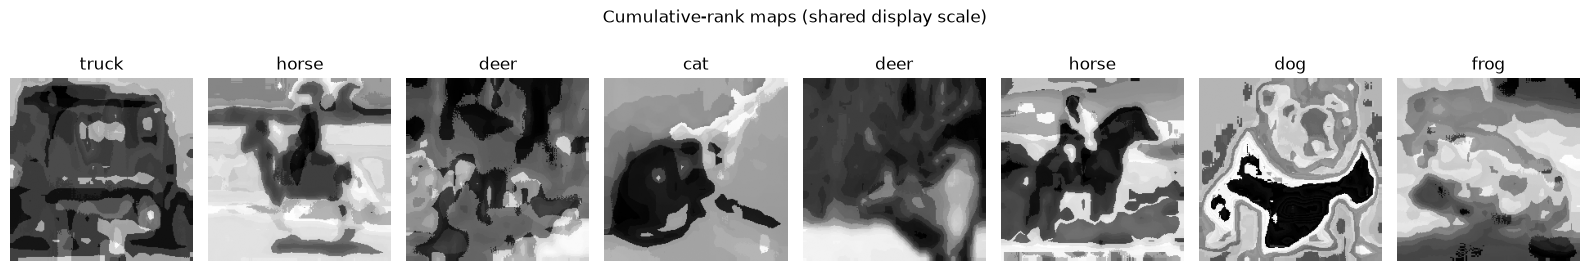

In [14]:
import matplotlib.pyplot as plt

x, y = next(iter(train_loader))
print(f"Images: {x.shape}; labels: {y.shape}")
# These are feature maps, not reconstructed RGB images.
raw_maps = x * CHANNEL_STD + CHANNEL_MEAN
count = min(8, len(raw_maps))
fig, axes = plt.subplots(1, count, figsize=(2 * count, 3), squeeze=False)
vmax = max(float(raw_maps[:count].max()), 1.0)
for i, axis in enumerate(axes[0]):
    axis.imshow(raw_maps[i, 0].numpy(), cmap="gray", vmin=0, vmax=vmax)
    axis.set_title(train_data.idx_to_class[y[i].item()])
    axis.axis("off")
fig.suptitle("Cumulative-rank maps (shared display scale)")
plt.tight_layout()
plt.show()


Check batch validity:

In [15]:
images, labels = next(iter(train_loader))

print(images.shape)  # torch.Size([32, 1, 224, 224])
print(images.dtype)  # torch.float32

print(labels.shape) # torch.Size([32])
print(labels.dtype) # torch.int64
print(labels[:5])

print([
    train_data.idx_to_class[label.item()]
    for label in labels[:5]
])

torch.Size([32, 1, 224, 224])
torch.float32
torch.Size([32])
torch.int64
tensor([8, 3, 7, 5, 5])
['ship', 'cat', 'horse', 'dog', 'dog']


# 3. The Model: Pre-Trained ResNet50
In a first try, the ResNet50 model is used. At first, only a fine tuning of the first and the last layers, for make the size compatible, is made

### Custom ResNet50 for single-channel input + additional features

The model used is derived from ResNet50 architecture. Its configuration is available in:

src/ml_setup/models.py 

The edits necessary are:

1.  **Modify the first convolutional layer (`conv1`)**: Change its `in_channels` from 3 (for RGB) to 1 (for `rank_cumulative_delta` channel). When loading pre-trained weights, we'll exclude the original `conv1` weights and initialize the new `conv1` layer.
2.  **Modify the final fully connected layer (`fc`)**: Edited to provide classification over the 10 classes.

In [16]:
# Run once for a new experiment OR to restore a checkpoint.
# Do not rerun this cell when merely adding epochs in the current session.

import math
import torch.nn as nn
from ml_setup.models import CustomResNet50

# load checkpoint (if any) and define the model
checkpoint = None 
if CHECKPOINT_TO_LOAD is not None:
    checkpoint = torch.load(CHECKPOINT_TO_LOAD, map_location="cpu", weights_only=True)
    if checkpoint.get("schema") != "resnet-validation-v1":
        raise ValueError("Checkpoint missing validation split or using a different split")
    if checkpoint.get("version") != VERSION or checkpoint.get("representation") != REPRESENTATION:
        raise ValueError("Checkpoint version/representation differs (legacy checkpoints need explicit migration).")
    if checkpoint.get("scale") != SCALE:
        raise ValueError("Checkpoint scale differs from the selected experiment.")

resnet_single_channel = CustomResNet50(num_classes=CONFIG["num_classes"], pretrained=checkpoint is None,
                                      in_channels=1, freeze_backbone=False).to(device)



# LR, loss, optimizer and scheduler setup
INITIAL_LR = CONFIG_NET["learning_rate"]
torch.manual_seed(CONFIG["model_seed"])

loss_fn = nn.CrossEntropyLoss()

# comment out for simple optimizer
#optimizer = torch.optim.SGD(
#    (p for p in resnet_single_channel.parameters() if p.requires_grad), lr=INITIAL_LR
#)

optimizer = torch.optim.SGD(
    (p for p in resnet_single_channel.parameters() if p.requires_grad),
    lr=INITIAL_LR,
    momentum=CONFIG_NET["momentum"],
    weight_decay=CONFIG_NET["weight_decay"]
)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, 
    factor=CONFIG_NET["scheduler_factor"],
    patience=CONFIG_NET["scheduler_patience"], 
    min_lr=CONFIG_NET["min_lr"],
    threshold=1e-4,
    threshold_mode="rel",
    cooldown=0
)


history = []
test_metrics = None
if checkpoint is not None:
    resnet_single_channel.load_state_dict(checkpoint["model_state_dict"], strict=True)
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
    history = checkpoint["history"]
    test_metrics = checkpoint.get("test_metrics")

best_val_loss = checkpoint["best_val_loss"] if checkpoint else float("inf")
best_epoch = checkpoint["best_epoch"] if checkpoint else None
best_model_state = checkpoint["best_model_state_dict"] if checkpoint else None


resnet_single_channel.eval()

if checkpoint is not None:
    torch.set_rng_state(checkpoint["torch_rng_state"])
    train_generator.set_state(checkpoint["loader_rng_state"])
    if torch.cuda.is_available() and checkpoint.get("cuda_rng_states"):
        if len(checkpoint["cuda_rng_states"]) == torch.cuda.device_count():
            torch.cuda.set_rng_state_all(checkpoint["cuda_rng_states"])


# check integrity of the checkpoint and the model
print("Completed epochs:", len(history))
print("Total parameters:", sum(p.numel() for p in resnet_single_channel.parameters()))
print("Trainable parameters:", sum(p.numel() for p in resnet_single_channel.parameters() if p.requires_grad))
print("Model ready. Run the single training cell below to add epochs.")



Completed epochs: 0
Total parameters: 23522250
Trainable parameters: 23522250
Model ready. Run the single training cell below to add epochs.


upload the checkpoint (if exists):

In [ ]:
# Every run will generate a new folder
from datetime import datetime
from copy import deepcopy

RUN_DIR = MODELS_DIR / f"valid_{VERSION}_Kmin{KMIN}_{datetime.now():%Y%m%d}"
RUN_DIR.mkdir(parents=True, exist_ok=False)

print("Checkpoints:", RUN_DIR)

Checkpoints: C:\Users\Edward\Desktop\AARHUS\output\models\valid_v4_Kmin32_20261030


# 4. Functions
Some functions helpful for repeated workflows

### 4.1 Training, testing and timing

Shared helpers return metrics; train_step also returns training_seconds.
The epoch loop and confusion-matrix plot remain below in the notebook.

In [21]:
from ml_setup.helper_functions import train_step, test_step, summarize_training_time


def save_checkpoint(filename):
    payload = {
        "schema": "resnet-validation-v1", **EXPERIMENT,
        "model_state_dict": resnet_single_channel.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "num_classes": CONFIG["num_classes"], "completed_epochs": len(history),
        "history": history, "normalization": normalization_stats,
        "idx_to_class": train_data.idx_to_class,
        "split_info": split_for_validation,
        "best_val_loss": best_val_loss, 
        "best_epoch": best_epoch,
        "best_model_state_dict": best_model_state,
        "test_metrics": test_metrics,
        "training_time": summarize_training_time(history),
        "torch_rng_state": torch.get_rng_state(),
        "loader_rng_state": train_generator.get_state(),
        "cuda_rng_states": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else [],
    }
    destination = RUN_DIR / filename
    temporary = destination.with_suffix(".pth.partial")
    torch.save(payload, temporary)
    temporary.replace(destination)


# 5. Training and Test loops


In [22]:
# Optional LR change; preserve the restored optimizer and its state.
NEW_LR = None  # Set a positive value (e.g. 0.01) to change LR explicitly.
if NEW_LR is not None:
    for group in optimizer.param_groups:
        group["lr"] = NEW_LR
print("Current learning rates:", [group["lr"] for group in optimizer.param_groups])


Current learning rates: [0.01]


In [22]:
from tqdm.auto import tqdm
from timeit import default_timer as timer

ADDITIONAL_EPOCHS = 10
if not isinstance(ADDITIONAL_EPOCHS, int) or ADDITIONAL_EPOCHS < 1:
    raise ValueError("ADDITIONAL_EPOCHS must be positive")
start_epoch = len(history)
end_epoch = start_epoch + ADDITIONAL_EPOCHS
start_time = timer()
test_metrics = None
for epoch in tqdm(range(start_epoch + 1, end_epoch + 1)):
    print(f"\nEpoch {epoch}/{end_epoch}")
    metrics = train_step(resnet_single_channel, train_loader, loss_fn, optimizer, device)
    print("Validation (the shared helper labels this evaluation 'Test'):")
    val_metrics = test_step(resnet_single_channel, val_loader, loss_fn, device,
                            num_classes=CONFIG["num_classes"])
    if not math.isfinite(val_metrics["loss"]):
        raise ValueError("Non-finite validation loss")
    history.append({"epoch": epoch, "loss": float(metrics["loss"]),
                    "accuracy": float(metrics["accuracy"]),
                    "val_loss": float(val_metrics["loss"]),
                    "val_accuracy": float(val_metrics["accuracy"]),
                    "validation_seconds": val_metrics["evaluation_seconds"],
                    "lr": float(optimizer.param_groups[0]["lr"]),
                    "training_seconds": metrics["training_seconds"],
                    "training_device": str(device)})
    if val_metrics["loss"] < best_val_loss:
        best_val_loss = float(val_metrics["loss"])
        best_epoch = epoch
        # Copia indipendente su CPU: non cambia quando il training prosegue.
        best_model_state = {k: v.detach().cpu().clone() for k, v in resnet_single_channel.state_dict().items()}
        save_checkpoint("best.pth")
        print(f"New best validation loss: {best_val_loss:.5f} (epoch {best_epoch})")
    save_checkpoint("last.pth")
print(f"Completed: {len(history)} epochs; elapsed: {timer() - start_time:.1f}s")
print("Best epoch:", best_epoch)
print("Resume with checkpoint_name =", str((RUN_DIR / "last.pth").relative_to(MODELS_DIR)))


  0%|          | 0/10 [00:00<?, ?it/s]


Epoch 1/10
Train loss: 1.46673 | Train accuracy: 48.67%
Validation (the shared helper labels this evaluation 'Test'):
Test loss: 1.33390 | Test accuracy: 55.06%
New best validation loss: 1.33390 (epoch 1)

Epoch 2/10
Train loss: 0.76966 | Train accuracy: 73.75%
Validation (the shared helper labels this evaluation 'Test'):
Test loss: 2.04480 | Test accuracy: 40.14%

Epoch 3/10
Train loss: 0.59978 | Train accuracy: 79.58%
Validation (the shared helper labels this evaluation 'Test'):
Test loss: 0.73269 | Test accuracy: 75.10%
New best validation loss: 0.73269 (epoch 3)

Epoch 4/10
Train loss: 0.49756 | Train accuracy: 82.99%
Validation (the shared helper labels this evaluation 'Test'):
Test loss: 0.52700 | Test accuracy: 81.68%
New best validation loss: 0.52700 (epoch 4)

Epoch 5/10
Train loss: 0.42219 | Train accuracy: 85.48%
Validation (the shared helper labels this evaluation 'Test'):
Test loss: 0.57085 | Test accuracy: 80.26%

Epoch 6/10
Train loss: 0.36417 | Train accuracy: 87.41%
V

Plot the behavior of the training loss function and the training accuracy

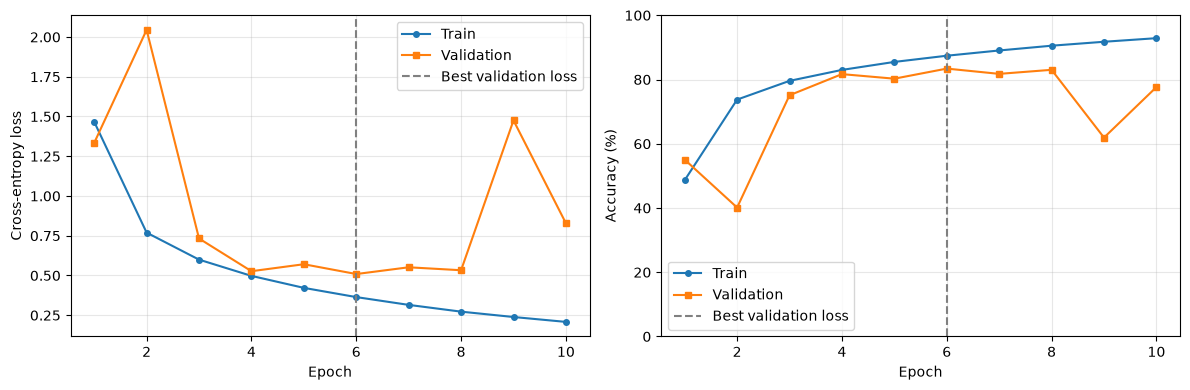

In [23]:
if not history:
    raise ValueError("Train or load a validation checkpoint first")
epochs = [row["epoch"] for row in history]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, key, title in zip(axes, ("loss", "accuracy"), ("Cross-entropy loss", "Accuracy (%)")):
    ax.plot(epochs, [r[key] for r in history], label="Train", marker="o", markersize=4)
    ax.plot(epochs, [r["val_" + key] for r in history], label="Validation", marker="s", markersize=4)
    if best_epoch is not None:
        ax.axvline(best_epoch, linestyle="--", color="gray", label="Best validation loss")
    ax.set(xlabel="Epoch", ylabel=title)
    ax.grid(alpha=0.3)
    ax.legend()
axes[1].set_ylim(0, 100)
fig.tight_layout()
plt.show()


Compute prediction over the test set and plot a confusion matrix

Best model (epoch 6) evaluation on test set:
Validation loss: 0.50917; accuracy: 83.40%
Test loss: 0.53095 | Test accuracy: 82.72%


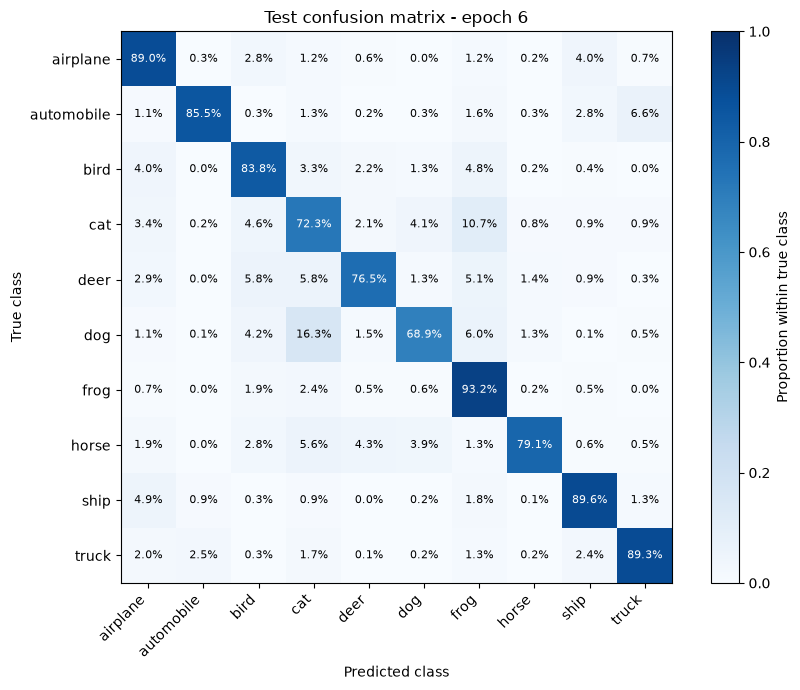

In [24]:
evaluation_model = deepcopy(resnet_single_channel).cpu()
evaluation_model.load_state_dict(best_model_state)
evaluation_model.to(device)
# Rows = true classes, columns = predicted classes. Each supported row sums to 1.
import numpy as np

num_classes = CONFIG["num_classes"]
class_names = [test_data.idx_to_class[i] for i in range(num_classes)]

print(f"Best model (epoch {best_epoch}) evaluation on test set:")
print(f"Validation loss: {best_val_loss:.5f}; accuracy: {history[best_epoch - 1]['val_accuracy'] / 100:.2%}")

# set "resnet_single_channel" instead of "evaluation_model" to evaluate the last checkpoint instead of the best one.
evaluation = test_step(evaluation_model, test_loader, loss_fn, device,
                       num_classes=num_classes)

confusion_counts = np.asarray(evaluation["confusion_counts"], dtype=np.int64)
support = confusion_counts.sum(axis=1, keepdims=True)
confusion_proportions = np.divide(confusion_counts, support,
    out=np.zeros_like(confusion_counts, dtype=np.float64), where=support != 0)
test_metrics = {"epoch": best_epoch, "loss": evaluation["loss"],
    "accuracy": evaluation["accuracy"],
    "confusion_counts": confusion_counts.tolist(),
    "confusion_proportions": confusion_proportions.tolist()}
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(confusion_proportions, cmap="Blues", vmin=0, vmax=1)
fig.colorbar(im, ax=ax, label="Proportion within true class")
ax.set(xticks=range(num_classes), yticks=range(num_classes),
       xticklabels=class_names, yticklabels=class_names,
       xlabel="Predicted class", ylabel="True class",
       title=f"Test confusion matrix - epoch {best_epoch}")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
for i in range(num_classes):
    for j in range(num_classes):
        value = confusion_proportions[i, j]
        label = f"{value:.1%}" if support[i, 0] else "N/A"
        ax.text(j, i, label, ha="center", va="center",
                color="white" if value > 0.5 else "black", fontsize=8)
fig.tight_layout()
plt.show()
# Diagonal = recall per class. N/A means that class is absent from this split.

del evaluation_model


# Saving and resume

best.pth is saved everytime the validation loss improves; last.pth is saved at each epoch.

In [25]:
# update last.pth with the test metrics as well
if not history or best_model_state is None:
    raise ValueError("No completed validation training to save")
save_checkpoint("last.pth")
print("Saved:", RUN_DIR / "last.pth")


Saved: C:\Users\Edward\Desktop\AARHUS\output\models\valid_v4_Kmin32_20261030\last.pth


### Load the model

To restore in a new session:
 1. Prepare data, normalization and the CustomResNet50 class.
 2. In the configuration cell, set CONFIG["checkpoint_name"] to the desired checkpoint filename and rerun setup.
 3. Execute that cell: it restores resnet_single_channel, optimizer and history.
 4. Execute the training cell to add epochs, or the confusion-matrix cell to evaluate.
 
Do not run a second model initialization after restoring.
